In [2]:
# Simulating one set of disturbance tests using the dynamic model from Case 1
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow import keras
from scipy.integrate import odeint
from simple_pid import PID

model = keras.models.load_model('nns_case1/prev_best_nn_13_10_400x')

# define two tank system model
def two_tanks(x,t,ut,Cait,Ft,Cact,Ftott,Vt):
    # States (3):
    # Flowrate of correction stream (m3/min)
    Fc = x[0]
    # Conc. of tank 1 outlet (kg/m3)
    Ca1 = x[1]
    # Conc. of tank 2 outlet (kg/m3)
    Ca2 = x[2]
    # Parameters:
    # Kv - Valve gain (m3/(min*controller_out_units))
    Kv = 0.01

    # tauV - Valve constant (min)
    tauV = 0.1

    # Calculate valve derivative
    dFcdt = (Kv/tauV)*ut - (1/tauV)*Fc

    # Calculate concentration in tank 1 derivative
    dCa1dt = (Ft/Vt[0])*Cait + (Cact/Vt[0])*Fc - (Ftott/Vt[0])*Ca1

    # Calculate Concentration in tank 2 derivative
    dCa2dt = (Ftott/Vt[1])*Ca1 - (Ftott/Vt[1])*Ca2

    # Return xdot:
    xdot = np.zeros(3)
    xdot[0] = dFcdt
    xdot[1] = dCa1dt
    xdot[2] = dCa2dt
    return xdot

In [3]:
# Define System and Time Evolution
Kp_arr = np.zeros(4000)
tauI_arr = np.zeros(4000)
tauD_arr = np.zeros(4000)
Kp_arr2 = np.zeros(4000)
tauI_arr2 = np.zeros(4000)
tauD_arr2 = np.zeros(4000)

# Volume of tank 1 and tank 2 (m3)
V = np.empty(2)
V[0] = 5
V[1] = 4
# Concentration of Initial Stream (kg/m3)
Cai_ss = 10
# Concentration of Correction Stream (kg/m3)
Cac_ss = 200
# Inlet Flowrate Initial Steady State (m3/min)
F_ss = 6.0 # On the training grid, so the static PID parameters can be looked up in the training database
# Correction Stream Initial Steady State (m3/min)
Fc_ss = 0.3
# Total flowrate (m3/min)
Ftot = F_ss + Fc_ss
# Time Interval (min)
t = np.linspace(0,99.9,4000)
# System Parameters
# Disturbance Variables (deviation form)
# Inlet Concentration (kg/m^3)
# Cai = np.ones(len(t)) * Cai_ss
# Inlet Flowrate (m3/min)
# F = np.ones(len(t)) * F_ss
# Initial Concentration of Tank 1 and of Tank 2 (kg/m3)
Ca1_ss = Ca2_ss = (F_ss * Cai_ss + Fc_ss * Cac_ss) / Ftot
# Controller output steady state
u_ss = Fc_ss/0.01 # For Kv = 0.01

# Define vectors
# Cai
Cai1 = np.linspace(Cai_ss,Cai_ss-2,300)
Cai2 = np.ones(200) * Cai1[-1]
Cai3 = np.linspace(Cai2[-1], Cai2[-1]-1, 250)
Cai4 = np.ones(250) * Cai3[-1]
Cai5 = (np.linspace(0,1.8,100) ** 2) + Cai4[-1]
Cai6 = np.ones(100) * Cai5[-1]
Cai7 = np.linspace(Cai6[-1],7,500)
Cai8 = np.ones(300) * Cai7[-1]
Cai9 = (np.linspace(-1,0.5,800) ** 2) + Cai8[-1]
Cai10 = np.linspace(0,0.5,200) + Cai9[-1]
Cai11 = (np.linspace(0,-1.5,300) ** 2) + Cai10[-1]
Cai12 = np.ones(200) * Cai11[-1]
Cai13 = (np.linspace(-1,0.5,200) ** 3) + Cai12[-1]
Cai14 = np.ones(300) * Cai13[-1]
Cai = np.concatenate((Cai1, Cai2, Cai3, Cai4, Cai5, Cai6, Cai7, Cai8, Cai9, Cai10, Cai11, Cai12, Cai13, Cai14))

# F
F1 = F_ss - ((np.linspace(0,1,200) ** 2) * 2)
F2 = ((np.linspace(0,-1,300) ** 3) * 1.5) + F1[-1]
F3 = np.ones(100) * F2[-1]
F4 = ((np.linspace(-1,2,400) ** 2) - 1) + F3[-1]
F5 = np.ones(200) * F4[-1]
F6 = np.linspace(F5[-1],2.3,500)
F7 = ((np.linspace(0,10,300) ** 0.5) * 0.5) + F6[-1]
F8 = ((np.linspace(0,5,200) ** 0.5) * 0.5) + F7[-1]
F9 = np.linspace(0,3,300) + F8[-1]
F10 = np.ones(200) * F9[-1]
F11 = ((((np.linspace(-1,0.2,300) ** 2) * 3) - 3) + F10[-1])
F12 = np.linspace(0,1.5,500) + F11[-1]
F13 = np.linspace(0,1,200) + F12[-1]
F14 = np.ones(300) * F13[-1]
F = np.concatenate((F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14))
# F10 = ((((np.linspace(-1,0.2,300) ** 2) * 2) - 2) + F9[-1])

# Cac
Cac1 = np.linspace(Cac_ss, Cac_ss + 10, 200)
Cac2 = np.ones(300) * Cac1[-1]
Cac3 = np.linspace(Cac2[-1], Cac2[-1] - 30, 200)
Cac4 = np.ones(300) * Cac3[-1]
Cac5 = ((np.linspace(0,5,300) ** 2) * (-2)) + Cac4[-1]
Cac6 = ((np.linspace(0,5,200) ** 2) * (2)) + Cac5[-1]
Cac7 = ((np.linspace(0,1,300) ** 2) * 20) + Cac6[-1]
Cac8 = np.ones(500) * Cac7[-1]
Cac9 = np.ones(200) * Cac8[-1]
Cac10 = ((np.linspace(-1,1,1000) ** 2) * 100) - 100 + Cac9[-1]
Cac11 = np.ones(500) * Cac10[-1]
Cac = np.concatenate((Cac1, Cac2, Cac3, Cac4, Cac5, Cac6, Cac7, Cac8, Cac9, Cac10, Cac11))

# setpoint
sp1 = np.ones(100) * Ca2_ss
sp2 = np.ones(900) * 22
sp3 = np.ones(500) * sp2[-1]
sp4 = np.ones(1000) * 15
sp5 = np.ones(500) * sp4[-1]
sp6 = np.linspace(sp5[-1], Ca2_ss, 800)
sp7 = np.ones(200) * Ca2_ss
sp = np.concatenate((sp1, sp2, sp3, sp4, sp5, sp6, sp7))
# sp = np.ones(len(t)) * (Ca2_ss + 1) # step change
u_bias = u_ss

tempdict_i = dict(F_df=F_ss, Cai_df=Cai_ss, Fc_df=Fc_ss, Cac_df = Cac_ss)
temp_i = pd.DataFrame(tempdict_i, index=[0])
a_i = model.predict(temp_i)
Kp_i = a_i[0,0]
tauI_i = a_i[0,1]
tauD_i = a_i[0,2]
Ki_i = Kp_i/tauI_i
Kd_i = Kp_i*tauD_i

# Initialize PID controller for the dynamic case (the NN updates its parameters at every timestep)
pid = PID(Kp_i,Ki_i,Kd_i)
# Set controller limits
umin = 0
umax = 50
pid.output_limits = (umin-u_bias,umax-u_bias)

# Static case: the PID parameters are taken from the training database, for the training system closest to the
# initial values (t = 0), and are kept for the whole simulation.
train_df = pd.read_csv('training_data_case1.csv')
inputs = ['F', 'Cai', 'Fc', 'Cac']
initial_values = np.array([F_ss, Cai_ss, Fc_ss, Cac_ss])
# Distance to every training system, with each variable scaled by its range so that all four count equally
input_range = train_df[inputs].max() - train_df[inputs].min()
distance = np.sqrt((((train_df[inputs] - initial_values) / input_range) ** 2).sum(axis=1))
static_system = train_df.loc[distance.idxmin()]
if distance.min() > 1e-6:
    print('The initial values are not in the training database. Using the closest training system:')
print(static_system[inputs + ['Kp', 'tauI', 'tauD']])
Kp_static = static_system['Kp']
tauI_static = static_system['tauI']
tauD_static = static_system['tauD']
Ki_static = Kp_static/tauI_static
Kd_static = Kp_static*tauD_static

# Initialize PID controller for the static case, with the same controller limits
pid_static = PID(Kp_static,Ki_static,Kd_static)
pid_static.output_limits = (umin-u_bias,umax-u_bias)


F         6.00000
Cai      10.00000
Fc        0.30000
Cac     200.00000
Kp       25.71462
tauI      5.63604
tauD      0.24019
Name: 61602, dtype: float64


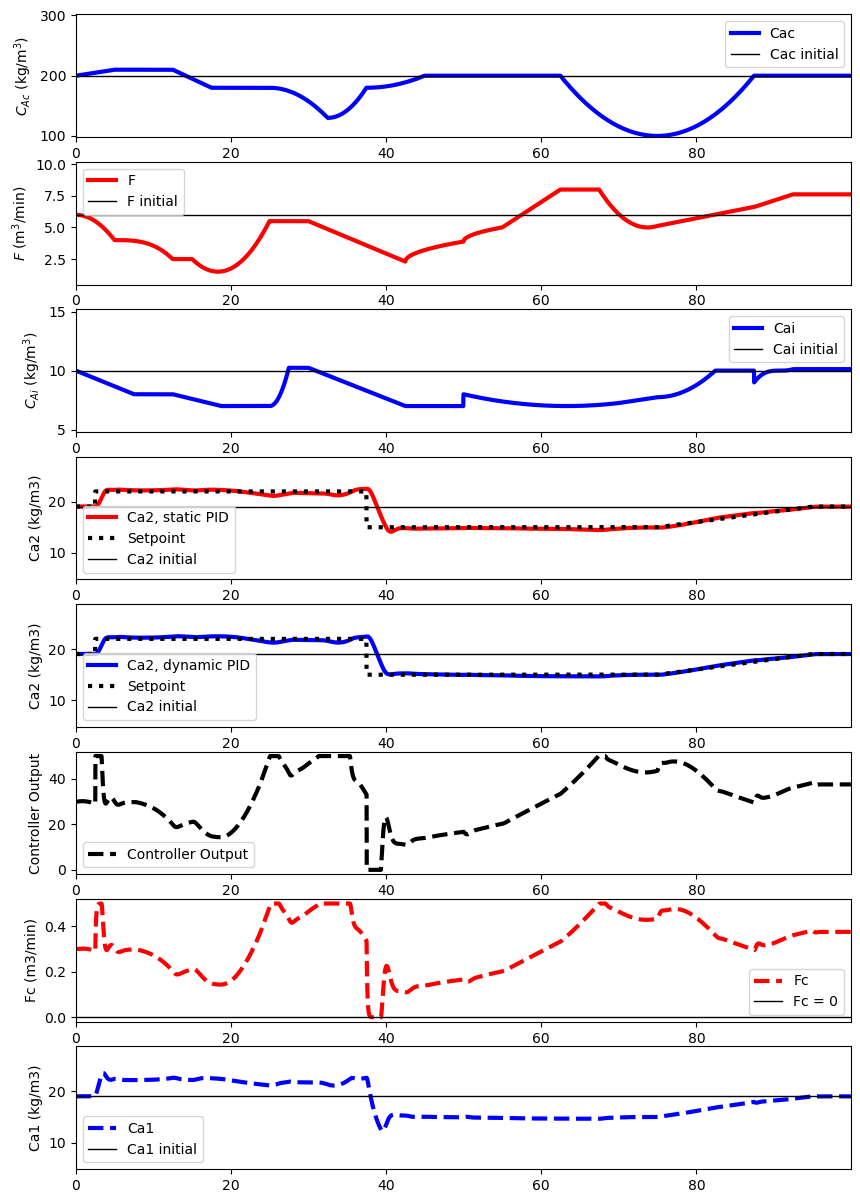

In [4]:
# Simulate tank system
def simulate(pid, update_with_nn):
    # Measured Variables
    Fc = np.ones(len(t)) * Fc_ss
    Ca1 = np.ones(len(t)) * Ca1_ss
    Ca2 = np.ones(len(t)) * Ca2_ss
    u = np.ones(len(t)) * u_ss

    # Declare vector to pass
    x0 = np.empty(3)
    x0[0] = Fc_ss
    x0[1] = Ca1_ss
    x0[2] = Ca2_ss

    for i in range(len(t)-1):
        # PID control
        pid.setpoint=sp[i] # Constantly updating setpoint

        # Dynamic case: the NN updates the PID parameters at every timestep. In the static case they are not updated.
        if update_with_nn:
            tempdict = dict(F_df=F[i], Cai_df=Cai[i], Fc_df=Fc[i], Cac_df = Cac[i])
            temp = pd.DataFrame(tempdict, index=[0])
            a = model.predict(temp)
            # ab2 = model2.predict(temp)

            pid.Kp = a[0,0]
            pid.Ki = a[0,0] / a[0,1]
            pid.Kd = a[0,0] * a[0,2]

            Kp_arr[i] = a[0,0]
            tauI_arr[i] = a[0,1]
            tauD_arr[i] = a[0,2]

#             Kp_arr2[i] = ab2[0,0]
#             tauI_arr2[i] = ab2[0,1]
#             tauD_arr2[i] = ab2[0,2]

        Ftot = F[i] + Fc[i]
        u[i+1] = pid(Ca2[i], t[i+1]-t[i]) + u_bias # The controller output becomes the input
        ts = [t[i],t[i+1]]
        y = odeint(two_tanks,x0,ts,args=(u[i+1],Cai[i],F[i],Cac[i],Ftot,V))
        Fc[i+1] = round(y[-1][0], 5) # two_tanks(x,t,ut,Cait,Ft,Cact,Ftott,Vt)
        Ca1[i+1] = round(y[-1][1], 5)
        Ca2[i+1] = round(y[-1][2], 5)
        x0[0] = Fc[i+1]
        x0[1] = Ca1[i+1]
        x0[2] = Ca2[i+1]

    return u, Fc, Ca1, Ca2

# Static case: the PID parameters stay at the values from the training database
u_static, Fc_static, Ca1_static, Ca2_static = simulate(pid_static, update_with_nn=False)
# Dynamic case: the NN updates the PID parameters at every timestep
u, Fc, Ca1, Ca2 = simulate(pid, update_with_nn=True)

# plot results
plt.figure(figsize=(10,15))

plt.subplot(8,1,1)
plt.plot(t,Cac,'b-',linewidth=3)
plt.ylabel(r'$C_{Ac}\ {\rm (kg/m^3)}$')
plt.plot([t[0],t[-1]],[Cac_ss,Cac_ss],'k-',linewidth=1)
plt.xlim(0, t[-1])
plt.ylim(98, 302)
plt.legend(['Cac','Cac initial'],loc='best')

plt.subplot(8,1,2)
plt.plot(t,F,'r-',linewidth=3)
plt.plot([t[0],t[-1]],[F_ss,F_ss],'k-',linewidth=1)
plt.ylabel(r'$F\ {\rm (m^3/min)}$')
plt.xlim(0, t[-1])
plt.ylim(0.48, 10.2)
plt.legend(['F','F initial'],loc='best')

plt.subplot(8,1,3)
plt.plot(t,Cai,'b-',linewidth=3)
plt.ylabel(r'$C_{Ai}\ {\rm (kg/m^3)}$')
plt.plot([t[0],t[-1]],[Cai_ss,Cai_ss],'k-',linewidth=1)
plt.xlim(0, t[-1])
plt.ylim(4.8, 15.2)
plt.legend(['Cai','Cai initial'],loc='best')

plt.subplot(8,1,4)
plt.plot(t,Ca2_static,'r-',linewidth=3)
plt.plot(t,sp,'k:',linewidth=3)
plt.plot([t[0],t[-1]],[Ca2_ss,Ca2_ss],'k-',linewidth=1)
plt.ylabel('Ca2 (kg/m3)')
plt.xlim(0, t[-1])
plt.ylim(4.8, 28.8)
plt.legend(['Ca2, static PID','Setpoint','Ca2 initial'],loc='best')

plt.subplot(8,1,5)
plt.plot(t,Ca2,'b-',linewidth=3)
plt.plot(t,sp,'k:',linewidth=3)
plt.plot([t[0],t[-1]],[Ca2_ss,Ca2_ss],'k-',linewidth=1)
# plt.plot([t[0],t[-1]],[1.0,1.0],'k-',linewidth=1)
# plt.plot([t[0],t[-1]],[1.1,1.1],'k-',linewidth=1)
plt.ylabel('Ca2 (kg/m3)')
plt.xlabel('Time (min)')
plt.xlim(0, t[-1])
plt.ylim(4.8, 28.8)
plt.legend(['Ca2, dynamic PID','Setpoint','Ca2 initial'],loc='best')

plt.subplot(8,1,6)
plt.plot(t,u,'k--',linewidth=3)
plt.ylabel('Controller Output')
plt.xlim(0, t[-1])
plt.ylim(-2, 52)
plt.legend(['Controller Output'],loc='best')

plt.subplot(8,1,7)
plt.plot(t,Fc,'r--',linewidth=3)
plt.plot([t[0],t[-1]],[0.0,0.0],'k-',linewidth=1)
plt.ylabel('Fc (m3/min)')
plt.xlim(0, t[-1])
plt.ylim(-0.02, 0.52)
plt.legend(['Fc','Fc = 0'],loc='best')

plt.subplot(8,1,8)
plt.plot(t,Ca1,'b--',linewidth=3)
plt.plot([t[0],t[-1]],[Ca1_ss,Ca1_ss],'k-',linewidth=1)
# plt.plot([t[0],t[-1]],[1.0,1.0],'k-',linewidth=1)
plt.ylabel('Ca1 (kg/m3)')
plt.xlim(0, t[-1])
plt.ylim(4.8, 28.8)
plt.legend(['Ca1','Ca1 initial'],loc='best')


In [5]:
tempdict = dict(F_df=F[len(t)-1], Cai_df=Cai[len(t)-1], Fc_df=Fc[len(t)-1], Cac_df = Cac[len(t)-1])
temp = pd.DataFrame(tempdict, index=[0])
a = model.predict(temp)
# ab2 = model2.predict(temp)
Kp_arr[-1] = a[0,0]
tauI_arr[-1] = a[0,1]
tauD_arr[-1] = a[0,2]
# Kp_arr2[-1] = ab2[0,0]
# tauI_arr2[-1] = ab2[0,1]
# tauD_arr2[-1] = ab2[0,2]

sp_er = sp - Ca2
sp_er_static = sp - Ca2_static
plot_data= np.vstack((t,Cac,F,Cai,u,Fc,Ca1,Ca2,sp,sp_er,Kp_arr,tauI_arr,tauD_arr,Kp_arr2,tauI_arr2,tauD_arr2,u_static,Fc_static,Ca1_static,Ca2_static,sp_er_static)) # vertical stack
plot_data = plot_data.T # transpose data
np.savetxt('data_for_simulation.txt',plot_data,delimiter=',',comments="",header='t,Cac,F,Cai,u,Fc,Ca1,Ca2,sp,sp_er,Kp,tauI,tauD,Kp2,tauI2,tauD2,u_static,Fc_static,Ca1_static,Ca2_static,sp_er_static')
# create animated GIF
# if make_gif:
#     imageio.mimsave('br_gif.gif', images)
#     #imageio.mimsave('animate.mp4', images) # requires ffmpeg

(0.0, 99.9)

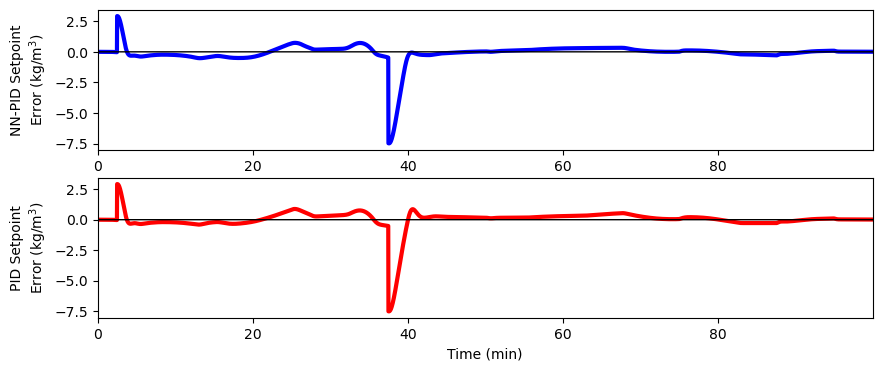

In [11]:
plt.figure(figsize=(10,4))  
# Plot the results
plt.subplot(2,1,1)
plt.plot(t,sp_er,'b-',linewidth=3)
plt.ylabel('NN-PID Setpoint\nError ' + r'${\rm (kg/m^3)}$')
plt.plot(t,np.zeros(len(t)),'k-',linewidth=1)
plt.xlim(0, t[-1])
# plt.ylim(ylimtry)
# plt.legend([r'$C_{Ac}$'],loc=4)

plt.subplot(2,1,2)
plt.plot(t,sp_er_static,'r-',linewidth=3)
plt.plot(t,np.zeros(len(t)),'k-',linewidth=1)
plt.ylabel('PID Setpoint\nError ' + r'${\rm (kg/m^3)}$')
plt.xlabel('Time (min)')
plt.xlim(0, t[-1])
# plt.ylim(ylimtry)
# plt.legend([r'$F$',],loc=4)